In [5]:
import pandas as pd

df = pd.read_csv("test.csv")
print(df.head(5))

   Class Index                                              Title  \
0            3                  Fears for T N pension after talks   
1            4  The Race is On: Second Private Team Sets Launc...   
2            4      Ky. Company Wins Grant to Study Peptides (AP)   
3            4      Prediction Unit Helps Forecast Wildfires (AP)   
4            4        Calif. Aims to Limit Farm-Related Smog (AP)   

                                         Description  
0  Unions representing workers at Turner   Newall...  
1  SPACE.com - TORONTO, Canada -- A second\team o...  
2  AP - A company founded by a chemistry research...  
3  AP - It's barely dawn when Mike Fitzpatrick st...  
4  AP - Southern California's smog-fighting agenc...  


In [ ]:
class_index_mapping = {
    1: "World",
    2: "Sports",
    3: "Business",
    4: "Sci/Tech"
}

so_df = pd.DataFrame({
    "input_text": df["Title"]+" "+df["Description"],
    "category": df["Class Index"].map(class_index_mapping)
}).sample(n=2000, random_state=42).reset_index(drop=True)

In [7]:

def generate_batches(sentences, batch_size=96):
    for i in range(0, len(sentences), batch_size):
        yield sentences[i:min(i + batch_size, len(sentences))]

In [8]:
input_texts = so_df["input_text"].tolist()

In [9]:
import cohere as co
import os
from dotenv import load_dotenv

load_dotenv()

client = co.Client(os.getenv("COHERE_API_KEY"))

def get_embeddings(sentences):
    try:
        response = client.embed(
            model="embed-english-v3.0",
            texts=sentences,
            input_type="clustering",
            embedding_types=["float"]
        )
        return response
    except Exception as e:
        print(f"Error occurred: {e}")
        return None

In [10]:
def encode_text_to_embeddings(sentences):
    try:
        response = get_embeddings(sentences)
        return [embedding for embedding in response.embeddings.float]
    except:
        return [None for _ in range(len(sentences))]

In [11]:
import time
batches = generate_batches(input_texts)

input_text_embeddings  = []

for batch in batches:
    input_text_embeddings.extend(encode_text_to_embeddings(batch))
    time.sleep(1)



In [12]:
input_text_embeddings = pd.DataFrame(input_text_embeddings)
print(input_text_embeddings.head(5))

       0         1         2         3         4         5         6     \
0  0.087097  0.019760  0.002441 -0.057892  0.000858 -0.039917 -0.008156   
1  0.006744  0.008629  0.021362  0.049164 -0.034668 -0.021301  0.029495   
2  0.060577 -0.015564  0.041565 -0.040802 -0.009773 -0.003998  0.017105   
3  0.017609 -0.007030 -0.001668  0.028610 -0.028870 -0.026077  0.048065   
4  0.032593  0.018814 -0.012466 -0.058350 -0.007561 -0.004799 -0.046661   

       7         8         9     ...      1014      1015      1016      1017  \
0 -0.028961 -0.019318  0.023148  ... -0.010132 -0.006977 -0.024918 -0.037445   
1 -0.054199  0.007679 -0.001722  ...  0.011055  0.006561  0.014893  0.008171   
2 -0.018524  0.021729 -0.029282  ...  0.038239 -0.006191  0.001986 -0.007973   
3 -0.009544  0.009506 -0.022552  ... -0.018600  0.007633 -0.000778 -0.019653   
4 -0.007214 -0.000362  0.043182  ...  0.028351 -0.009819 -0.003206 -0.007702   

       1018      1019      1020      1021      1022      1023  
0 -0

In [13]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [14]:
n_clusters = 4
kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=0,
    n_init='auto'
).fit(input_text_embeddings)

In [15]:
kmeans_labels = kmeans.labels_

In [16]:
PCA_model = PCA(n_components=2)
PCA_model.fit(input_text_embeddings)
new_values = PCA_model.transform(input_text_embeddings)

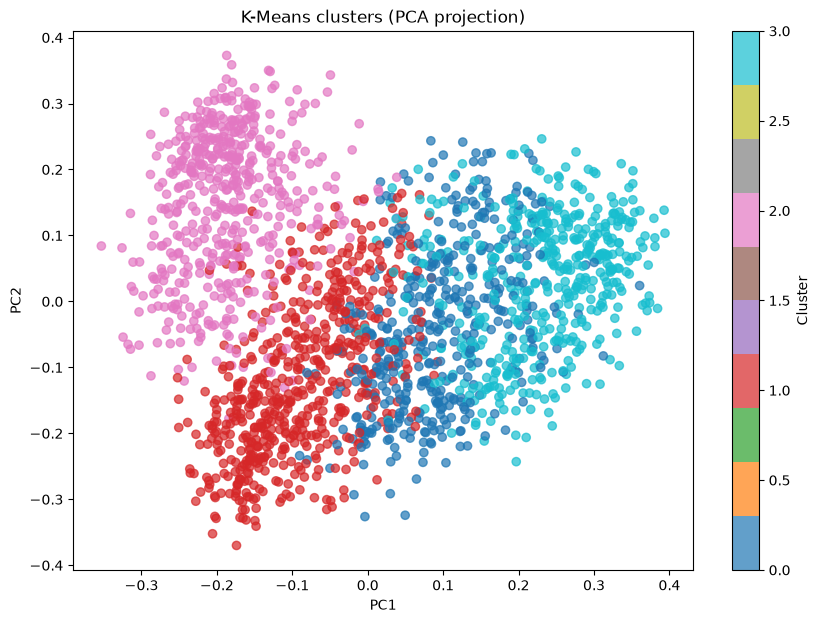

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    new_values[:, 0],
    new_values[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    alpha=0.7
)
ax.set(title="K-Means clusters (PCA projection)", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=ax, label="Cluster")
plt.show()


In [36]:
from sklearn.ensemble import IsolationForest

In [37]:
clf = IsolationForest(contamination=0.005, 
                      random_state=4)

In [38]:
preds = clf.fit_predict(input_text_embeddings)
print(f"{len(preds)} predictions. Set of possible values: {set(preds)}")

2000 predictions. Set of possible values: {np.int64(1), np.int64(-1)}


In [39]:
so_df.loc[preds==-1]

,input_text,category
107,"Williams Rejects Deal, Says He Won #39;t Retur...",Sports
584,"\$904,800 in refund checks go undelivered in S...",Business
826,SafeGuard Offers Easy Hard-Drive Protection Up...,Sci/Tech
1124,Cosatu to meet over conflict with ANC The Cong...,World
1341,Bloglines aims for simplicity (SiliconValley.c...,Sci/Tech
1394,Seattle Mariners Minor League Report - August ...,Sports
1583,GlobeTrotter: Mandrake-based 40GB Linux Mobile...,Sci/Tech
1820,MOTOR RACING: FERRARI IN TALK FURY FERRARI are...,Sports
1876,"Israelis Trudge Home, in Shock After Bombings ...",World
1991,Jets #39; Moss Questionable For Sunday Hempste...,Sports


In [40]:
from sklearn.ensemble import RandomForestClassifier

In [41]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [42]:
X = input_text_embeddings

In [44]:
y = so_df["category"].values
print(y)

<StringArray>
[  'Sports',    'World', 'Sci/Tech', 'Sci/Tech', 'Sci/Tech', 'Business',
    'World', 'Business', 'Sci/Tech', 'Business',
 ...
 'Sci/Tech',   'Sports',    'World', 'Business',    'World', 'Sci/Tech',
 'Sci/Tech', 'Sci/Tech', 'Sci/Tech', 'Sci/Tech']
Length: 2000, dtype: str


In [45]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=4)

In [46]:
clf = RandomForestClassifier(n_estimators=200)

In [47]:
clf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
y_pred = clf.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.875


In [54]:
# choose a number between 0 and 1999
i = 1005
label = so_df.loc[i,'category']
question = so_df.loc[i,'input_text']

# get the embedding of this question and predict its category
question_embedding = get_embeddings([question]).embeddings.float
pred = clf.predict(question_embedding)

print(f"For question {i}, the prediction is `{pred[0]}`")
print(f"The actual label is `{label}`")
print("The question text is:")
print("-"*50)
print(question)

For question 1005, the prediction is `Business`
The actual label is `Business`
The question text is:
--------------------------------------------------
Two hurricanes = two deductibles Many homeowners in the Orlando area suffered a double blow when hurricanes Charley and Frances struck in quick succession. Now, they #39;re smarting from a financial one-two punch - two insurance deductibles.
